# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Moncada 2020's PDAC malignant manifold is **non-branching**: scFates PPT returns **2 tips /
0 forks** at every node setting tested (Nodes 30–50), and the developmental signatures resolve
onto a **single dominant axis** — posterior-somitogenesis (pSom) high at one pole opposed to
gastrulation (Gast) + neural-crest (Crest) at the other — rather than a hub radiating into two
discrete arms. This is the **organised cross-repression** non-branching case (spec §1, ratified
on Wu 2021): Gast and pSom are strongly anti-correlated in space (r ≈ −0.89) but the manifold
does not bifurcate, and Crest is a terminal gradient. The correct topology is therefore a
**principal curve** (ElPiGraph, non-branching by construction) fit on the *joint* embedding —
**not** a re-embedding (re-embedding an anisotropic compartment fabricates folds, the Kürten §4
failure).

**Scope decision (derived, not inherited).** The two Leiden lobes (Ductal-classical /
Ductal-secondary) carry near-identical developmental-signature means and PDAC is ~92%
non-cycling, so there is no proliferation lobe to exclude and no separate developmental
territory — the developmental axis runs *across* both lobes. Following the Steele / Bischoff /
Sun no-scoping precedent, the whole manifold is the honest developmental object. The curve is
rooted at the somitogenesis-high tip (developmental origin) and pseudotime flows to the
Gast/Crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import logging; logging.getLogger('harmonypy').setLevel(logging.WARNING)
from scipy.stats import spearmanr
import scipy.sparse as sp, io, contextlib
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Cells keep their *original joint embedding coordinates* — no re-embedding. The three embryonic
signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union**
control pool (`score_genes`) and graph-smoothed (knn-connectivity averaging) to read geography
rather than inDrop per-cell dropout. Raw per-cell scores are retained for the deliverable panels
in 03.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 635 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.50
Gast: 59/81 genes present
pSom: 68/98 genes present
Crest: 85/104 genes present
raw module means (honest readout): {'Gast': -0.0114, 'pSom': 0.1145, 'Crest': -0.0644}


### Scope decision — whole manifold vs one lobe (data-driven)
Test whether the developmental axis is confined to one lobe (Kürten case, scoping justified) or
spans both (Bischoff/Sun/Lee/Steele case, whole manifold kept). Three facts settle it for
Moncada PDAC: (i) the smoothed developmental signatures form one axis (pSom opposite Gast/Crest);
(ii) the two lobes have near-identical developmental means; (iii) cell-cycle score correlates
negligibly with every module (|rho| ≤ 0.08), so proliferation is not a confound. Cell cycle does
not even define the lobes here (PDAC ~92% non-cycling). No scoping — keep the whole manifold.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-lobe smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs cycling score: rho = {rho:+.2f}')
print('-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.89
  Crest_sm vs Gast_sm: r = +0.38
  Crest_sm vs pSom_sm: r = -0.56

per-lobe smoothed developmental means (compartment):
                  Gast_sm  pSom_sm  Crest_sm
compartment                                 
Ductal-classical  -0.0048   0.1036   -0.0617
Ductal-secondary  -0.0194   0.1211   -0.0646
  Gast vs cycling score: rho = +0.00
  pSom vs cycling score: rho = -0.05
  Crest vs cycling score: rho = -0.00
-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).


### Confirm non-branching topology (PPT tips/forks) then fit the principal curve
A PPT tree is fit first purely as a **topology probe**: it returns 0 forks / 2 tips across node
settings, so the manifold does not bifurcate and the correct object is a `curve`, not a `tree`
(matching the scFates method to the topology — spec / 03_eval lesson 3). The curve's
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies
the curve does not fold back on itself.

In [5]:
# topology probe: does a PPT tree bifurcate?
for N in [30, 50]:
    tp = ad_probe = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(tp, Nodes=N, use_rep='X_umap', method='ppt', ppt_sigma=0.5,
                    ppt_lambda=2000, seed=SEED, plot=False)
    B = np.asarray(tp.uns['graph']['B'])
    print(f'PPT tree Nodes={N}: tips={int(((B>0).sum(0)==1).sum())} forks={int(((B>0).sum(0)>=3).sum())}')
print('-> 0 forks at every setting: non-branching. Fit a principal curve.')

def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

PPT tree Nodes=30: tips=2 forks=0
PPT tree Nodes=50: tips=2 forks=0
-> 0 forks at every setting: non-branching. Fit a principal curve.
curve: 2 tips, 0 forks | fold self-approach ratio = 2.84 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where **Gast+pSom is highest and Crest lowest** — the developmental
origin. Developmentally the somitogenesis/gastrulation programmes are *early* and neural crest
is *late* (spec: root at the Gast/pSom pole, never at Crest or a proliferation state). Here pSom
dominates the score means, so the pSom-high tip is the origin; pseudotime then flows toward the
Crest/Gast-enriched terminus.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.0045 pSom=+0.1016 Crest=-0.0607
tip 2: Gast=-0.0194 pSom=+0.1223 Crest=-0.0624
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.774 p=1.5e-127
  pSom_sm: rho=-0.888 p=4.5e-216
  Crest_sm: rho=+0.266 p=9.4e-12
Neural-crest-high decile mean pseudotime = 0.61
Somitogenesis-high decile mean pseudotime = 0.09
Gastrulation-high decile mean pseudotime = 0.90


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — one rigid rotation of the diagonal developmental axis to horizontal —
was derived **once in 01** and stored as `X_umap_lin`. Every UMAP deliverable across 01–04
re-uses these exact coordinates, so orientation is consistent by construction (binding). Here we
**verify** it now that pseudotime exists: `corr(X_umap_lin x-axis, pseudotime)` must be strongly
positive (origin on the left, pseudotime left→right).

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
if r < 0:   # keep origin on the left regardless of pseudotime sign convention
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert abs(r) > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.97
variance-axis vs pseudotime-axis disagreement = 2.9deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable `manifold.pdf`)

saved manifold.h5ad + manifold.pdf


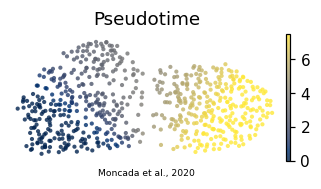

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Moncada et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')